In [1]:
import tensorflow as tf

cifar10 = tf.keras.datasets.cifar10 # import data image 

# split data 
(x_train, y_train), (x_test_val, y_test_val) = cifar10.load_data()
print("x_train.shape: ", x_train.shape)
print("y_train.shape: ", y_train.shape)
print("x_test_val.shape: ", x_test_val.shape)
print("y_test_val.shape: ", y_test_val.shape)

x_train.shape:  (50000, 32, 32, 3)
y_train.shape:  (50000, 1)
x_test_val.shape:  (10000, 32, 32, 3)
y_test_val.shape:  (10000, 1)


In [2]:
# all class 10 
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

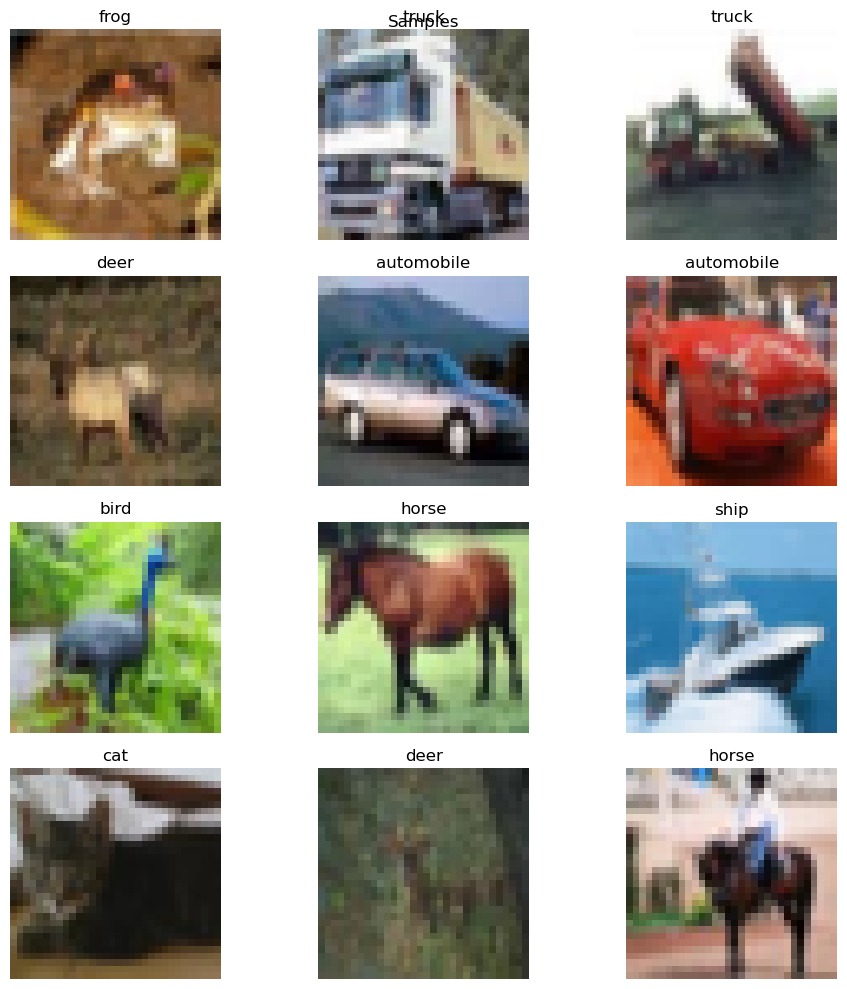

In [3]:
import matplotlib.pyplot as plt

def show_samples(data, labels):
    # fig  يسمح لنا بالوصول الى خصائص الشبكة 
    # axes  مصفوفة  numPy  تحتوي على 3 اعمدة 
    fig, axes = plt.subplots(4, 3, figsize=(10, 10))

    axes = axes.flatten()

    for i in range(len(axes)):
        
        axes[i].imshow(data[i])
        
        class_index=labels[i][0]
        
        class_name=class_names[class_index]
        axes[i].set_title(class_name)
        
        # ازالة تسميات المحاور مع المعامل  off 
        axes[i].axis('off')  
    
    #  ضبط الاضهار 
    plt.tight_layout()
    
    fig.suptitle("Samples")
    
    plt.show()

show_samples(x_train, y_train)

In [4]:
from sklearn.model_selection import train_test_split

x_test , x_val ,y_test , y_val = train_test_split(x_test_val ,y_test_val , test_size=0.5)

In [5]:
x_train = x_train /255.0
x_test = x_test /255.0
x_val = x_val /255.0

In [6]:
from keras.models import Sequential

from keras.layers import Conv2D , MaxPooling2D , Flatten , Dense , Dropout , Input

model =Sequential()

# تحديد ابعاد الصورة 
model.add(Input(shape=(32 , 32 ,3)))

# filters يحاول ان يتعلم في كل مرة عدد من الميزات  kernel_size ابعاد  النواة : لمسح الصورة حساب الجداء الداخلي 
model.add(Conv2D(filters=32 , kernel_size=(3,3) ,activation='relu'  )) # طبقة تلاففية مننوع  2D

#  من افضل الممارسات الجيدةوضع عدةطبقات 

# Conv2D  For Images 
model.add(Conv2D(filters=32, kernel_size=(3,3), activation='relu'))

model.add(MaxPooling2D(pool_size=(2,2)))

# تمنع مشكلة التحصيص  overfiting 
model.add(Dropout(0.25))   #  طبقة التسريب 

model.add(Conv2D(64 ,(3,3) , activation='relu'))
model.add(Conv2D(64 ,(3,3) , activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Dropout(0.25))

# طبقة من نوع مسطح 
model.add(Flatten()) #من مصفوفة ثنائية الى احادية 


model.add(Dense(512, activation='relu'))

model.add(Dropout(0.25))

# طبقةكثيفةمع 10 عقد  لان لدينا 10 مخرجات  
model.add(Dense(10 ,activation='softmax')) # softmax    الدالة المناسبة في متعددة الاصناف  

model.compile(optimizer='adam' , loss='sparse_categorical_crossentropy', metrics=['accuracy'])




          


In [7]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input

model = Sequential()

model.add(Input(shape=(32, 32, 3)))

model.add(Conv2D(filters=32, kernel_size=(3, 3), activation='relu'  ))

model.add(Conv2D(32, (3, 3), activation='relu'))

model.add(MaxPooling2D(pool_size=(2, 2)))

model.add(Dropout(0.25))

model.add(Conv2D(64, (3, 3), activation='relu' ))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.25))

model.add(Flatten())

model.add(Dense(512, activation='relu'))

model.add(Dropout(0.5))

#  طبقة كثيفية مع 10 عقد 
model.add(Dense(10, activation='softmax'))

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [8]:
history = model.fit(x_train , y_train, batch_size=128 , epochs=20 , validation_data=(x_val , y_val))

Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 37s 89ms/step - accuracy: 0.3956 - loss: 1.6377 - val_accuracy: 0.5340 - val_loss: 1.2951
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 34s 87ms/step - accuracy: 0.5477 - loss: 1.2640 - val_accuracy: 0.6014 - val_loss: 1.1217
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 33s 85ms/step - accuracy: 0.6076 - loss: 1.1049 - val_accuracy: 0.6640 - val_loss: 0.9537
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 34s 86ms/step - accuracy: 0.6505 - loss: 0.9936 - val_accuracy: 0.6898 - val_loss: 0.8985
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 33s 85ms/step - accuracy: 0.6784 - loss: 0.9174 - val_accuracy: 0.7084 - val_loss: 0.8316
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 32s 82ms/step - accuracy: 0.6987 - loss: 0.8556 - val_accuracy: 0.7246 - val_loss: 0.7961
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 32s 81ms/step - accuracy: 0.7194 - loss: 0.7994 - val_accuracy: 0.7340 - val_loss: 0.7444
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 37s 94ms/step - accuracy: 0.7339 - loss: 0.7543 - 

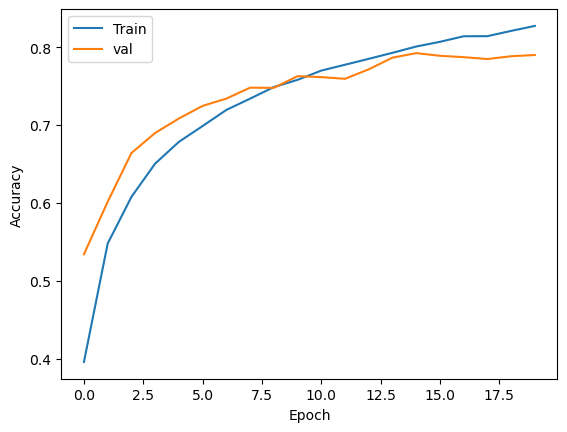

In [9]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'val'] )
plt.show()

In [10]:
loss , accuracy = model.evaluate(x_test,y_test)
print("Accuracy on test set: ",accuracy)
print('loss on test set : ',loss)

157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.7924 - loss: 0.6437
Accuracy on test set:  0.7924000024795532
loss on test set :  0.6437363028526306


In [11]:
!pip install scikeras

In [12]:
import pandas as pd 
from keras.models import Sequential
from keras.layers import Conv2D, MaxPool2D, Flatten, Dense, Dropout, Input
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import GridSearchCV

def create_model(filters=32,
                 kernel_size=(3,3),
                 pool_size=(2,2),
                 activation='relu',
                 optimizer='adam',
                 dropout_rate=0.25,
                 dense_units=512,
                 dense_dropout_rate=0.5):
    
    model = Sequential()
    
    # تحديد المدخلات
    model.add(Input(shape=(32, 32, 3)))
    
    # المجموعات التلافيفية الأولى
    model.add(Conv2D(filters=filters, kernel_size=kernel_size, activation=activation))
    model.add(Conv2D(filters=filters, kernel_size=kernel_size, activation=activation))
    model.add(MaxPool2D(pool_size=pool_size))
    model.add(Dropout(dropout_rate)) # إضافة الدوب آوت بشكل صحيح
    
    # المجموعات التلافيفية الثانية
    model.add(Conv2D(filters=2*filters, kernel_size=kernel_size, activation=activation))
    model.add(Conv2D(filters=2*filters, kernel_size=kernel_size, activation=activation))
    model.add(MaxPool2D(pool_size=pool_size))
    model.add(Dropout(dropout_rate))
    
    # تحويل البيانات إلى متجه تمهيداً للطبقات الكثيفة (Dense Layers)
    model.add(Flatten())
    
    # الطبقات التصنيفية العميقة
    model.add(Dense(128, activation=activation))
    model.add(Dropout(dense_dropout_rate))
    
    # طبقة المخرجات  بناء على 10 فئات )
    model.add(Dense(10, activation='softmax'))
    
    # تجميع النموذج
    model.compile(optimizer=optimizer, 
                  loss='sparse_categorical_crossentropy', 
                  metrics=['accuracy'])
    
    return model

#  البحث التلقائي عن أفضل تركيبة من الإعدادات (Hyperparameters)

In [13]:
'''
model_class_keras = KerasClassifier(model=create_model, verbose=0) # تخبر النموذج ألا يطبع تفاصيل التدريب (مثل الـ Epochs

param_grid = {
    'model__filters': [32, 64],  
    'model__kernel_size': [(3, 3),(4,4) ],
    'model__pool_size': [(2, 2), (4,4)],
    'model__activation': ['relu'],
    'model__optimizer': ['adam'],
    'model__loss': ['sparse_categorical_crossentropy'],
    'model__dropout_rate': [0.2, 0.25],
    'model__dense_units': [256, 512],
    'model__dense_dropout_rate': [0.4, 0.5]
}
# هذا يسمى النمط الثنائي (Double Underscore). تخبر به أداة البحث: "اذهبي إلى المتغير داخل الغلاف model وقومي بتغيير البارامتر الذي يليه
# " (مثلاً: مرري القيمة 32 ثم 64 إلى البارامتر filters داخل دالتك).


# اختبار النموذج على نفس بيانات التدريب يعطي نتائج مخادعة. لذلك نستخدم الـ Cross-Validation
cv =5

# إنشاء الكائن المسؤول عن عملية البحث الشامل (Grid Search)
grid = GridSearchCV(estimator=model_class_keras, param_grid=param_grid, cv=cv, verbose=0)

grid_result = grid.fit(x_train, y_train)

result_df = pd.DataFrame(grid_result.cv_results)
result_df.to_csv('grid_search_results-2.csv' , index=False)

'''

'\nmodel_class_keras = KerasClassifier(model=create_model, verbose=0) # تخبر النموذج ألا يطبع تفاصيل التدريب (مثل الـ Epochs\n\nparam_grid = {\n    \'model__filters\': [32, 64],  \n    \'model__kernel_size\': [(3, 3),(4,4) ],\n    \'model__pool_size\': [(2, 2), (4,4)],\n    \'model__activation\': [\'relu\'],\n    \'model__optimizer\': [\'adam\'],\n    \'model__loss\': [\'sparse_categorical_crossentropy\'],\n    \'model__dropout_rate\': [0.2, 0.25],\n    \'model__dense_units\': [256, 512],\n    \'model__dense_dropout_rate\': [0.4, 0.5]\n}\n# هذا يسمى النمط الثنائي (Double Underscore). تخبر به أداة البحث: "اذهبي إلى المتغير داخل الغلاف model وقومي بتغيير البارامتر الذي يليه\n# " (مثلاً: مرري القيمة 32 ثم 64 إلى البارامتر filters داخل دالتك).\n\n\n# اختبار النموذج على نفس بيانات التدريب يعطي نتائج مخادعة. لذلك نستخدم الـ Cross-Validation\ncv =5\n\n# إنشاء الكائن المسؤول عن عملية البحث الشامل (Grid Search)\ngrid = GridSearchCV(estimator=model_class_keras, param_grid=param_grid, cv=cv, verb

In [14]:
# grid_reult.best_params_

In [ ]:
from keras.models import Sequential
from keras.layers import Conv2D, MaxPool2D, Flatten, Dropout, Input, Dense # تم إضافة Dense هنا

# يجب عليك تعريف هذه المتغيرات قبل استخدامها
kernel_size = (3, 3)
activation = 'relu'
optimizer = 'adam'

model = Sequential()

# تحديد المدخلات
model.add(Input(shape=(32, 32, 3)))

# المجموعات التلافيفية الأولى
model.add(Conv2D(filters=64, kernel_size=kernel_size, activation=activation))
model.add(Conv2D(filters=64, kernel_size=kernel_size, activation=activation))
model.add(MaxPool2D(pool_size=(2, 2))) # تم إغلاق القوس
model.add(Dropout(0.2))

# المجموعات التلافيفية الثانية
model.add(Conv2D(filters=128, kernel_size=kernel_size, activation=activation))
model.add(Conv2D(filters=128, kernel_size=kernel_size, activation=activation))
model.add(MaxPool2D(pool_size=(2, 2))) # تم إغلاق القوس
model.add(Dropout(0.2))

# تحويل البيانات إلى متجه
model.add(Flatten())

# الطبقات التصنيفية العميقة
model.add(Dense(512, activation=activation))
model.add(Dropout(0.4))

# طبقة المخرجات
model.add(Dense(10, activation='softmax'))

# تجميع النموذج
model.compile(optimizer=optimizer, 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

history = model.fit(x_train, y_train, batch_size=128, epochs=25, validation_data=(x_val, y_val))

Epoch 1/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 103s 259ms/step - accuracy: 0.4211 - loss: 1.5793 - val_accuracy: 0.5676 - val_loss: 1.2263
Epoch 2/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 106s 271ms/step - accuracy: 0.5866 - loss: 1.1561 - val_accuracy: 0.6628 - val_loss: 0.9697
Epoch 3/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 109s 279ms/step - accuracy: 0.6645 - loss: 0.9483 - val_accuracy: 0.6950 - val_loss: 0.8788
Epoch 4/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 112s 286ms/step - accuracy: 0.7130 - loss: 0.8135 - val_accuracy: 0.7236 - val_loss: 0.8079
Epoch 5/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 110s 280ms/step - accuracy: 0.7388 - loss: 0.7368 - val_accuracy: 0.7592 - val_loss: 0.6981
Epoch 6/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 103s 262ms/step - accuracy: 0.7676 - loss: 0.6621 - val_accuracy: 0.7648 - val_loss: 0.6894
Epoch 7/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 106s 271ms/step - accuracy: 0.7867 - loss: 0.6094 - val_accuracy: 0.7838 - val_loss: 0.6352
Epoch 8/25
391/391 ━━━━━━━━━━━━━━━━━━━━ 110s 280ms/step - accuracy: 0.8027 -

In [ ]:
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

print("Train Acc : ",train_accuracy)
print("Validation Acc : ",val_accuracy)

In [ ]:
model.save('cifar10_trained_model_2.keras')

In [ ]:
from keras.models import load_model

model = load_model('cifar10_trained_model.keras')

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

num_images = 20
x_test_selected = x_test[:num_images]
y_test_selected = y_test[:num_images]

predictions = model.predict(x_test_selected)
predicted_labels = np.argmax(predictions, axis=1)

fig, axes = plt.subplots(4, 5, figsize=(12, 10))
axes = axes.ravel()

for i in range(num_images):
    
    axes[i].imshow(x_test_selected[i])
    axes[i].axis('off')
    
    predicted_label = class_names[predicted_labels[i]]
    true_label = class_names[y_test_selected[i][0]]
    
    if predicted_label == true_label:
        title_color = 'green'
    else:
        title_color = 'red'
    
    axes[i].set_title(f'Pred: {predicted_label}\nTrue: {true_label}', color=title_color)

plt.tight_layout()
plt.show()

In [ ]:
for i in range(10):
    image =x_test[i]
    label = class_numes[y_test[i][0]

    file_name = f'imae_{i}_label_{label}.png'
    plt.imsave(file_name,image)

In [ ]:
image_path = 'image_6_label_bird.pnh'

In [ ]:
from tensorflow.keras.preprocessing.image import img_to_array, load_img
import numpy as np

image = load_img(image_path, target_size=(32, 32))

image_array = img_to_array(image)

image_array = np.expand_dims(image_array, axis=0)

image_array = image_array / 255.0

In [ ]:
image_array.shape

In [ ]:
predictions = model.predict([image_array])
# print(predictions[0])

predicted_class = np.argmax(predictions[0])

predicted_label = class_names[predicted_class]

In [ ]:
plt.imshow(image)
plt.title(predicted_label)
plt.axis('off')
plt.show()